# SPUS v2 tutorial workflow

This notebook is organized into four sections:

1. baseline inference with `spus-pde-unet-36m-v2`
2. user fine-tuning from that baseline
3. inference and evaluation of the user checkpoint
4. optional comparison against the three Hugging Face fine-tuned models


In [1]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
from spus_ft import (
    evaluate_rollout,
    fine_tune,
    infer_rollout,
    plot_multiple_rollout_mse_curves,
    plot_rollout_frames,
    plot_rollout_mse_curve,
)

dataset_path = Path("/usr/projects/artimis/cahrens/tut-aux/spus-ft-data/FNS-KF/FNS-KF.nc")
models_root = Path("/usr/projects/artimis/cahrens/tut-aux/spus-models")

pretrained_v2_model_dir = models_root / "spus-pde-unet-36m-v2"
hf_finetuned_model_dir = models_root / "spus-pde-unet-36m-v2-fns-kf"
hf_finetuned_model_dir_32 = models_root / "spus-pde-unet-36m-v2-fns-kf-32"
hf_finetuned_model_dir_256 = models_root / "spus-pde-unet-36m-v2-fns-kf-256"

comparison_output_dir = Path("/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs")

fns_kf_channel_names = [
    "horizontal velocity",
    "vertical velocity",
    "padding channel 2",
    "padding channel 3",
    "padding channel 4",
]


**Channel note**

For FNS-KF, only channels `0` and `1` are physical variables: `horizontal velocity` and `vertical velocity`.
Channels `2`, `3`, and `4` are constant padding channels added so the data matches the 5-channel SPUS input format, so they should not be interpreted physically and will look visually blank or uniform in plots.


## Looking at the data

Before running baseline inference or fine-tuning, we first make a couple of simple trajectory plots so people get a sense of what the FNS-KF data looks like and how much data there is.

The assembled `FNS-KF.nc` file contains **20,000 trajectories**, each with **21 time steps**, **2 physical channels** (`horizontal velocity` and `vertical velocity`), and a **128 × 128** spatial grid.

These plots are meant as a quick visual orientation step before we move on to baseline inference, user fine-tuning, and model comparison.


/vast/projects/artimis/cahrens/tut/src/spus_ft/plotting.py:506: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout(rect=(0.0, 0.12, 1.0, 0.88))


{'figure': <Figure size 2000x1700 with 26 Axes>,
 'axes': array([[<Axes: title={'center': 'Time 0'}>,
         <Axes: title={'center': 'Time 1'}>,
         <Axes: title={'center': 'Time 2'}>,
         <Axes: title={'center': 'Time 3'}>,
         <Axes: title={'center': 'Time 4'}>],
        [<Axes: title={'center': 'Time 5'}>,
         <Axes: title={'center': 'Time 6'}>,
         <Axes: title={'center': 'Time 7'}>,
         <Axes: title={'center': 'Time 8'}>,
         <Axes: title={'center': 'Time 9'}>],
        [<Axes: title={'center': 'Time 10'}>,
         <Axes: title={'center': 'Time 11'}>,
         <Axes: title={'center': 'Time 12'}>,
         <Axes: title={'center': 'Time 13'}>,
         <Axes: title={'center': 'Time 14'}>],
        [<Axes: title={'center': 'Time 15'}>,
         <Axes: title={'center': 'Time 16'}>,
         <Axes: title={'center': 'Time 17'}>,
         <Axes: title={'center': 'Time 18'}>,
         <Axes: title={'center': 'Time 19'}>],
        [<Axes: title={'cente

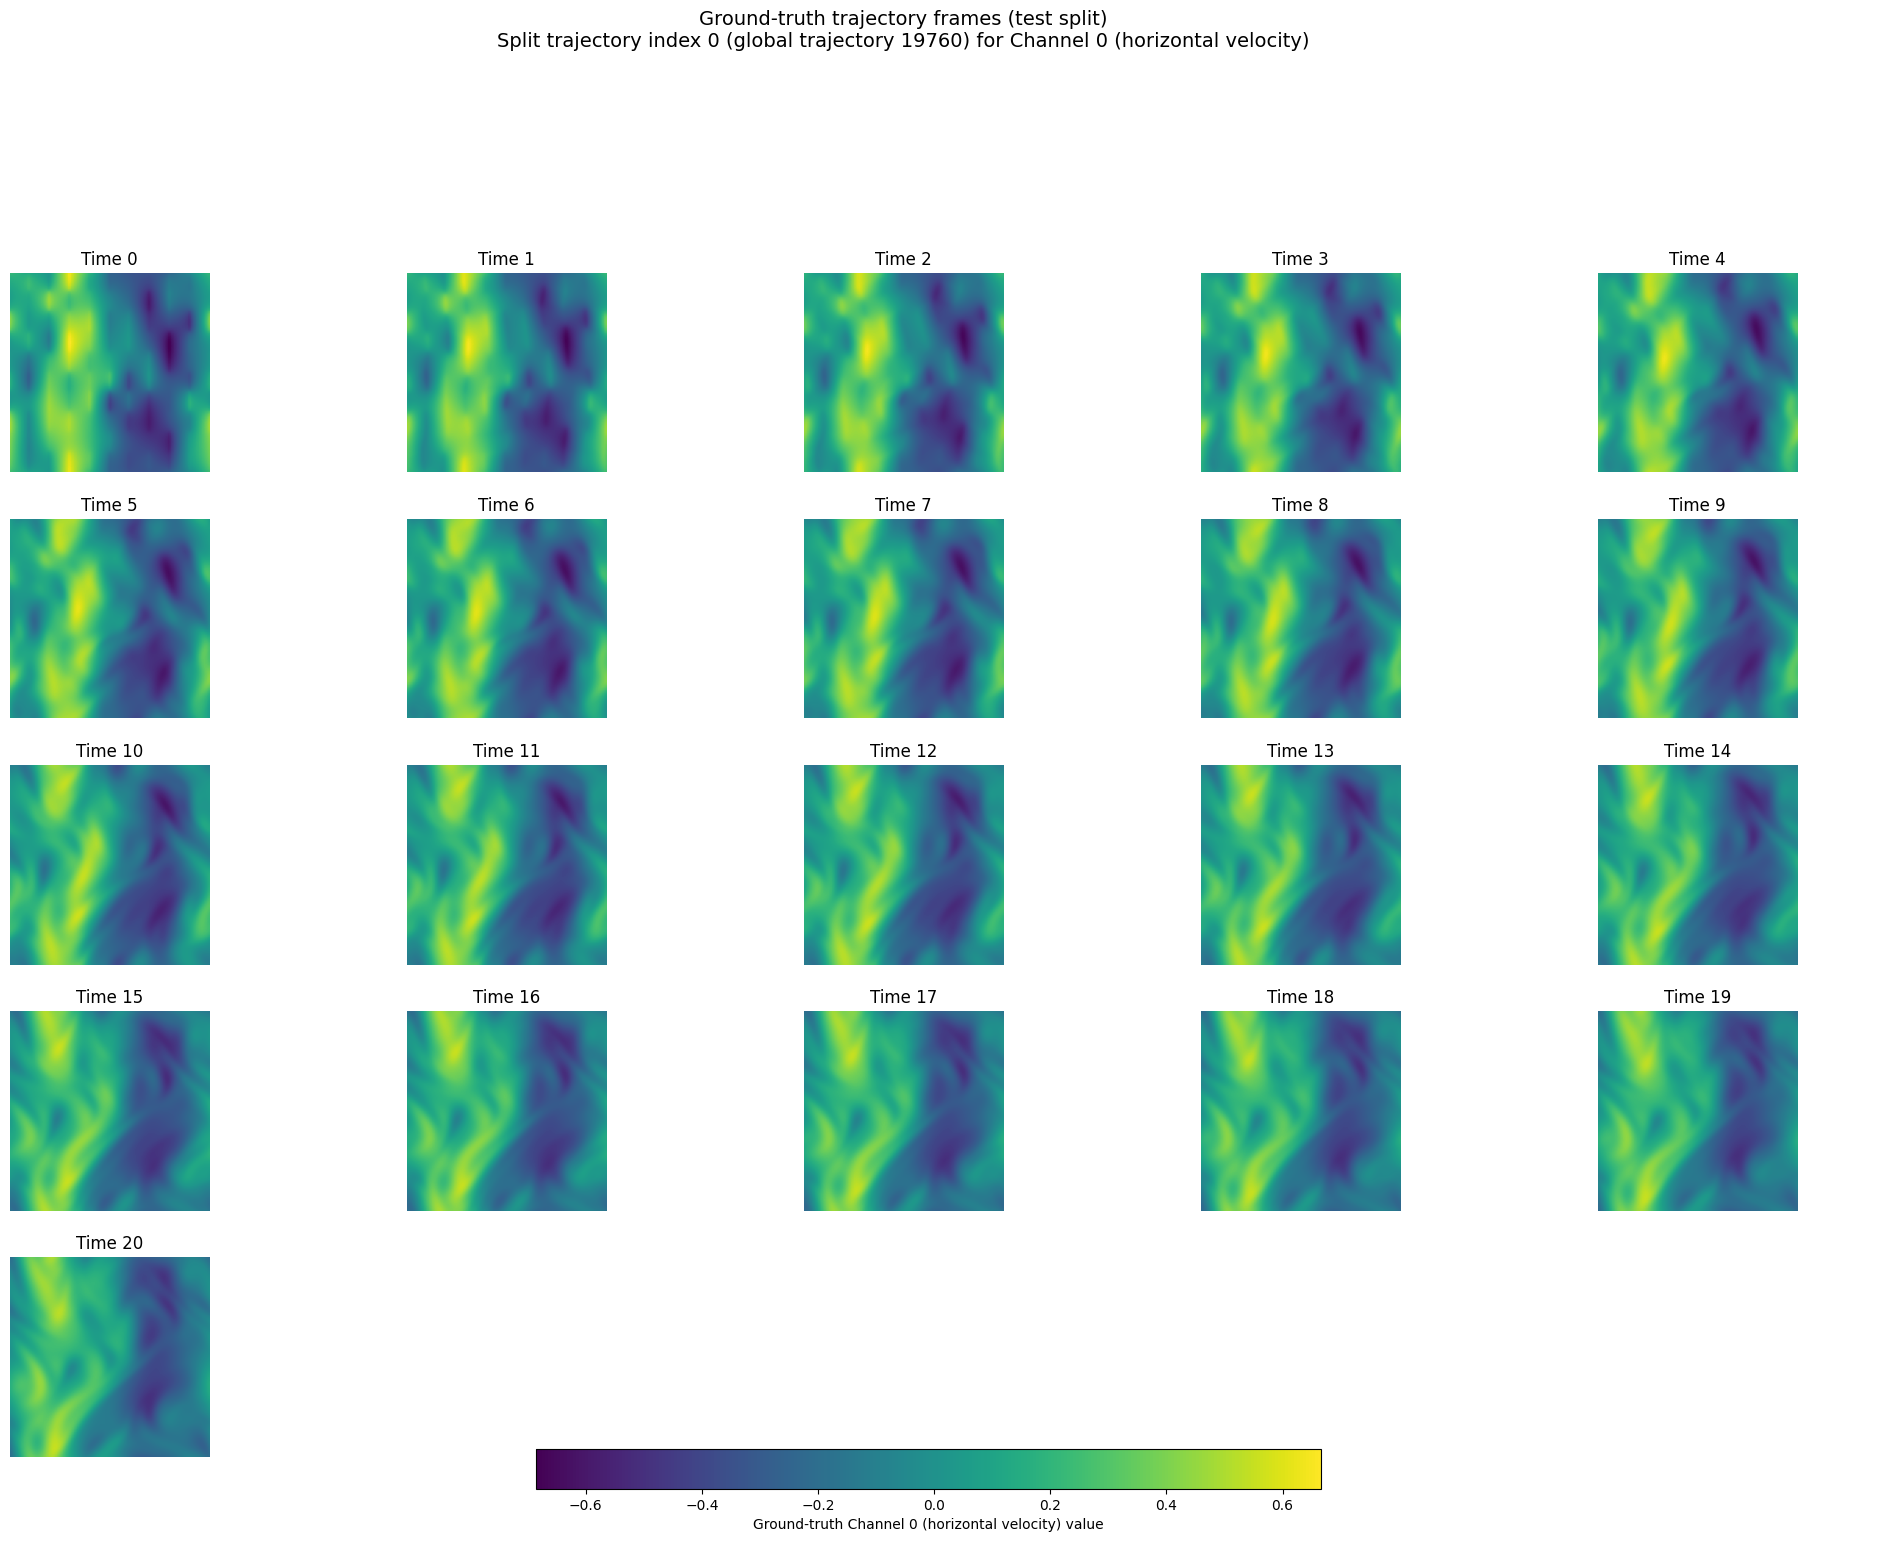

In [2]:
#Plot a trajectory to get a sense of what is in there
from spus_ft import plot_ground_truth_trajectory_frames

plot_ground_truth_trajectory_frames(
    dataset_path="/usr/projects/artimis/cahrens/tut-aux/spus-ft-data/FNS-KF/FNS-KF.nc",
    split_name="test",
    split_trajectory_index=0,
    channel_index=0,
    channel_names=fns_kf_channel_names,
    max_columns=5,
    save_path="/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/test_truth_traj0_ch0.png",
)

{'figure': <Figure size 2000x1700 with 26 Axes>,
 'axes': array([[<Axes: title={'center': 'Time 0'}>,
         <Axes: title={'center': 'Time 1'}>,
         <Axes: title={'center': 'Time 2'}>,
         <Axes: title={'center': 'Time 3'}>,
         <Axes: title={'center': 'Time 4'}>],
        [<Axes: title={'center': 'Time 5'}>,
         <Axes: title={'center': 'Time 6'}>,
         <Axes: title={'center': 'Time 7'}>,
         <Axes: title={'center': 'Time 8'}>,
         <Axes: title={'center': 'Time 9'}>],
        [<Axes: title={'center': 'Time 10'}>,
         <Axes: title={'center': 'Time 11'}>,
         <Axes: title={'center': 'Time 12'}>,
         <Axes: title={'center': 'Time 13'}>,
         <Axes: title={'center': 'Time 14'}>],
        [<Axes: title={'center': 'Time 15'}>,
         <Axes: title={'center': 'Time 16'}>,
         <Axes: title={'center': 'Time 17'}>,
         <Axes: title={'center': 'Time 18'}>,
         <Axes: title={'center': 'Time 19'}>],
        [<Axes: title={'cente

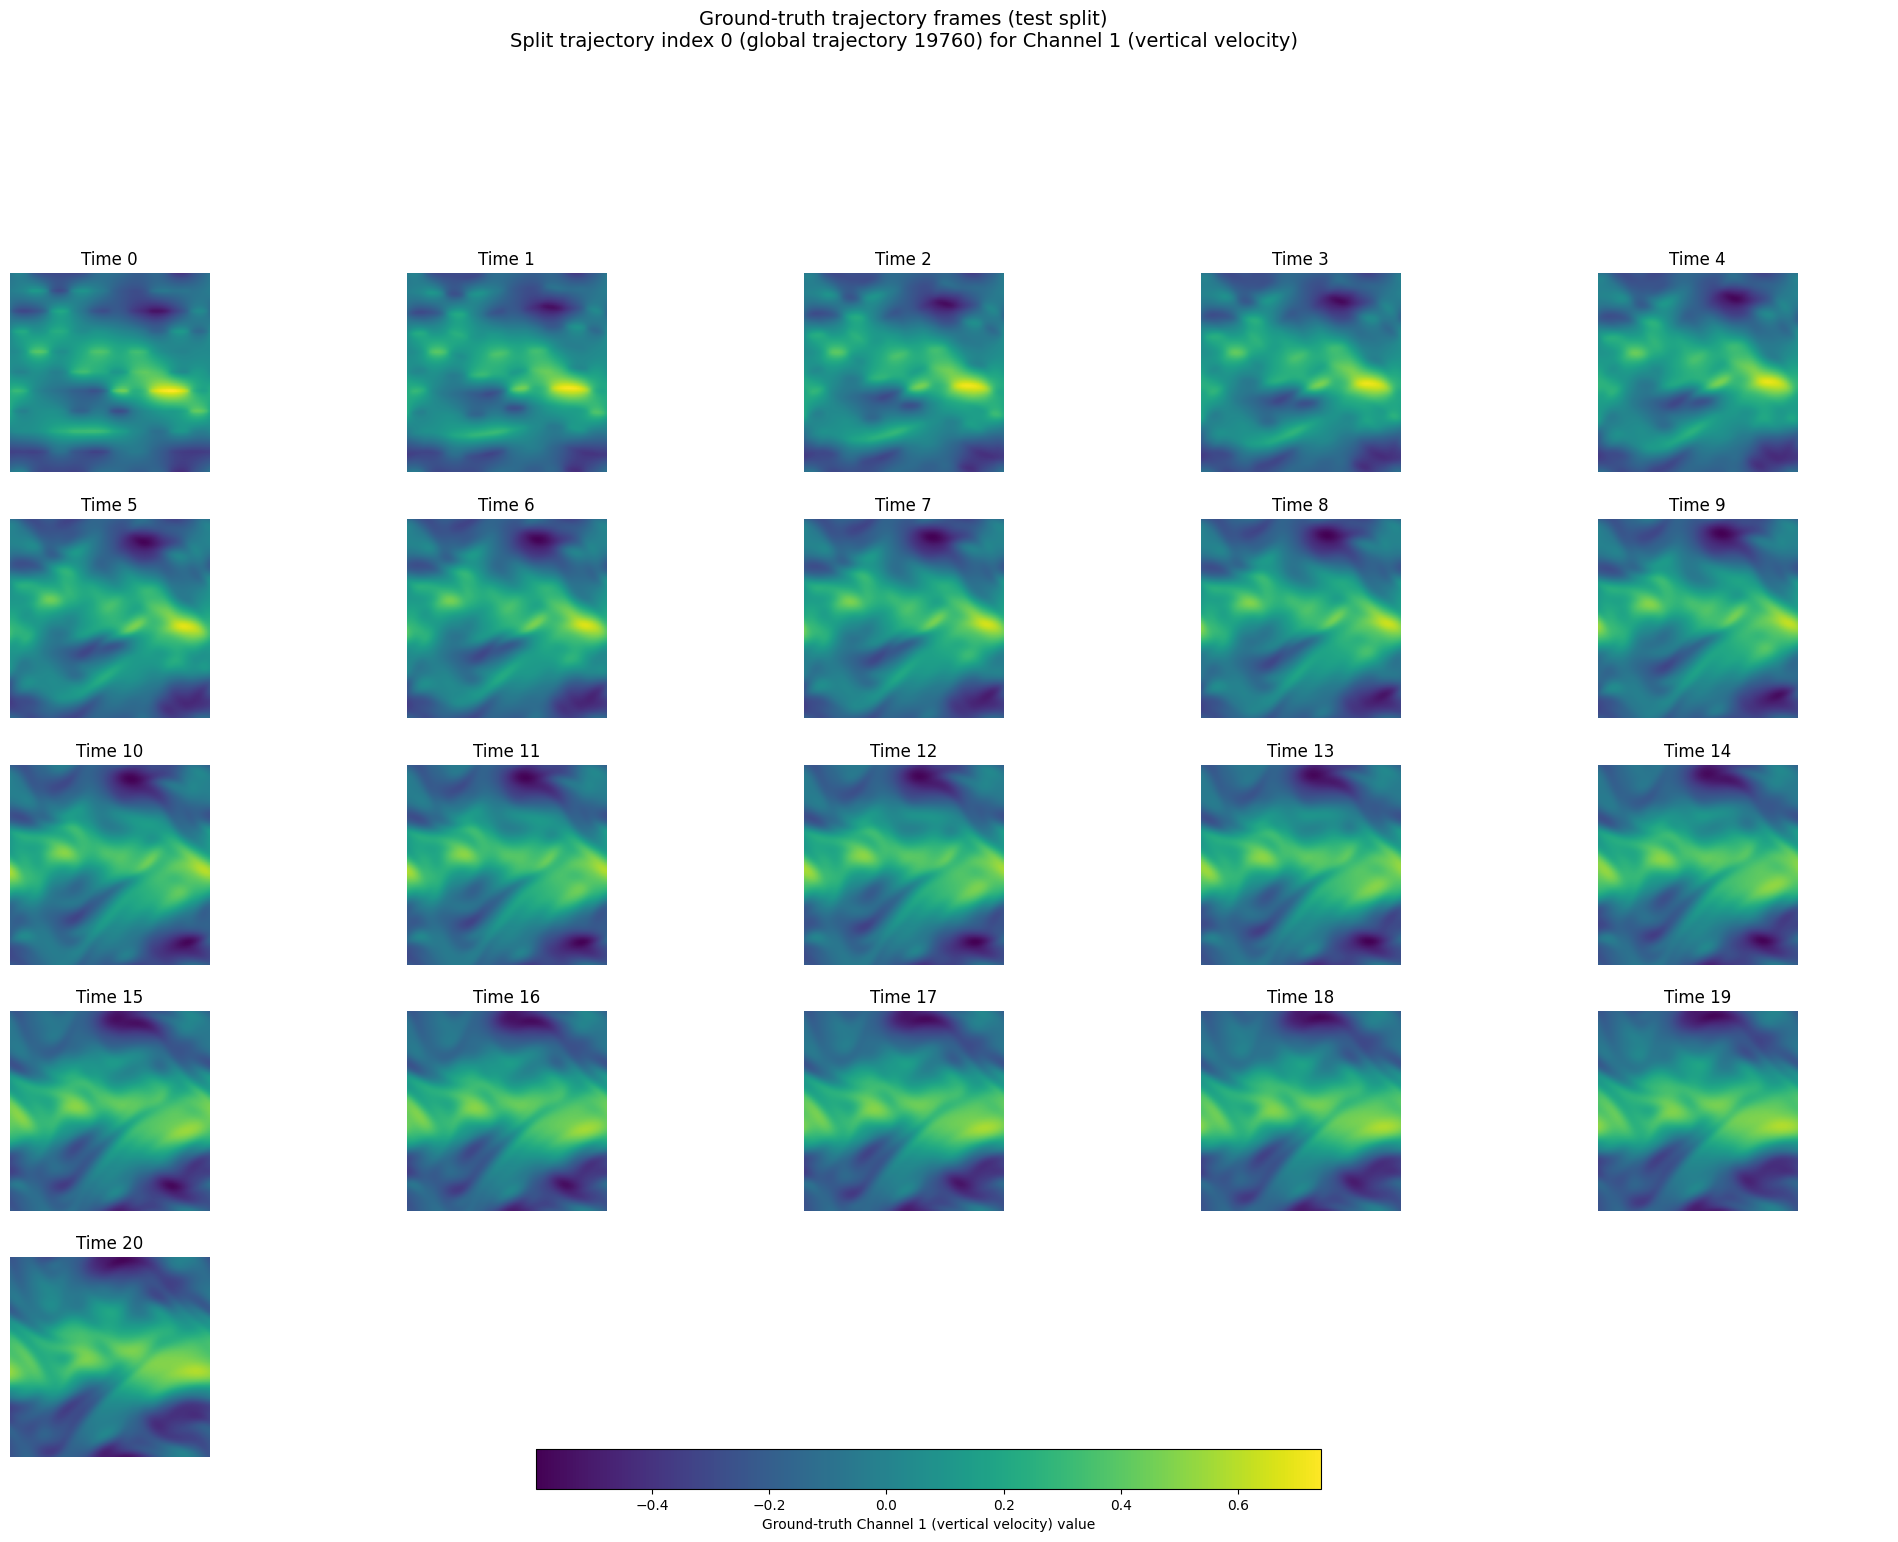

In [3]:
# Plot the same test trajectory for channel 1 (vertical velocity)
plot_ground_truth_trajectory_frames(
    dataset_path="/usr/projects/artimis/cahrens/tut-aux/spus-ft-data/FNS-KF/FNS-KF.nc",
    split_name="test",
    split_trajectory_index=0,
    channel_index=1,
    channel_names=fns_kf_channel_names,
    max_columns=5,
    save_path="/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/test_truth_traj0_ch1.png",
)


## 1. Baseline inference with `spus-pde-unet-36m-v2`

Run one autoregressive rollout with the pretrained SPUS U-Net v2 baseline on a test trajectory.


In [4]:
baseline_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=pretrained_v2_model_dir,
)

baseline_rollout_outcome


/vast/projects/artimis/cahrens/tut/.venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights from local directory


{'run_dir': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261022-234820'),
 'predictions_path': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261022-234820/rollout.pt'),
 'summary_path': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_pretrained_20261022-234820/summary.json'),
 'summary': {'average_mse': 2513093.149193439,
  'timestep_mse': [0.2059851097572465,
   2.8676391436638937,
   9.415862504772184,
   34.98682716360767,
   108.38847464197747,
   317.7713054372087,
   887.149267784416,
   2284.51346282949,
   5679.8557027033985,
   14084.43470574554,
   34195.59363968084,
   81172.62636714352,
   184000.01622920795,
   404730.39242357214,
   844589.6413503034,
   1858776.3880028627,
   3927023.023340217,
   7428430.1220382005,
   13266602.538447972,
   22208933.05279656],
  'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym

/vast/projects/artimis/cahrens/tut/src/spus_ft/plotting.py:294: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout(rect=(0.0, 0.20, 1.0, 0.93))


{'figure': <Figure size 1200x750 with 8 Axes>,
 'axes': array([[<Axes: title={'center': 'Predicted step 1'}>,
         <Axes: title={'center': 'Predicted step 8'}>,
         <Axes: title={'center': 'Predicted step 16'}>],
        [<Axes: title={'center': 'True step 1'}>,
         <Axes: title={'center': 'True step 8'}>,
         <Axes: title={'center': 'True step 16'}>]], dtype=object),
 'subtitle': Text(0.5, 0.16, 'Top row uses prediction range. Bottom row uses ground-truth range.'),
 'prediction_colorbar': <matplotlib.colorbar.Colorbar at 0x14fee0684fa0>,
 'target_colorbar': <matplotlib.colorbar.Colorbar at 0x14fee0684f70>,
 'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'split_name': 'test',
  'split_strategy': 'fns_kf_paper',
  'num_train_trajectories': 1,
  'requested_test_trajectory_index': 0,
  'selected_test_trajectory_index': 19760,
  'test_trajectory_indices': [19760],
  'num_test_trajectories': 1,
  's

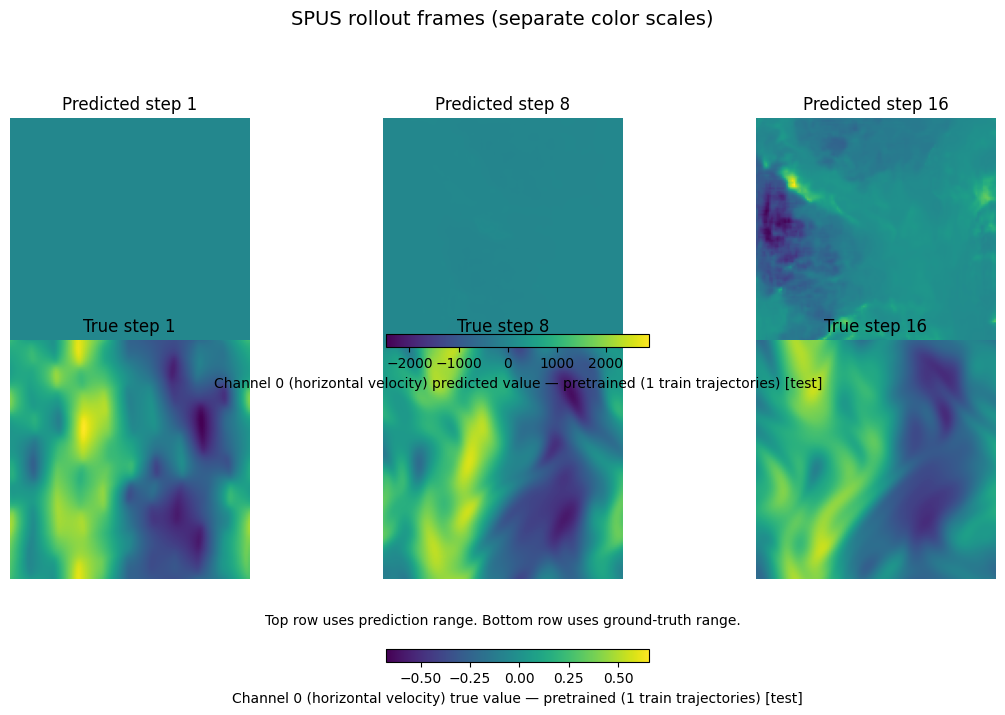

In [5]:
from spus_ft import plot_rollout_frames_separate_scales

plot_rollout_frames_separate_scales(
    run_dir=baseline_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=baseline_rollout_outcome["run_dir"] / "baseline_v2_fig3_like_separate_scales.png",
)


In [6]:
baseline_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=hf_finetuned_model_dir_256,
)


Loading weights from local directory


{'figure': <Figure size 1200x750 with 8 Axes>,
 'axes': array([[<Axes: title={'center': 'Predicted step 1'}>,
         <Axes: title={'center': 'Predicted step 8'}>,
         <Axes: title={'center': 'Predicted step 16'}>],
        [<Axes: title={'center': 'True step 1'}>,
         <Axes: title={'center': 'True step 8'}>,
         <Axes: title={'center': 'True step 16'}>]], dtype=object),
 'subtitle': Text(0.5, 0.16, 'Top row uses prediction range. Bottom row uses ground-truth range.'),
 'prediction_colorbar': <matplotlib.colorbar.Colorbar at 0x14ff00164670>,
 'target_colorbar': <matplotlib.colorbar.Colorbar at 0x14ff001de0d0>,
 'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'split_name': 'test',
  'split_strategy': 'fns_kf_paper',
  'num_train_trajectories': 1,
  'requested_test_trajectory_index': 0,
  'selected_test_trajectory_index': 19760,
  'test_trajectory_indices': [19760],
  'num_test_trajectories': 1,
  's

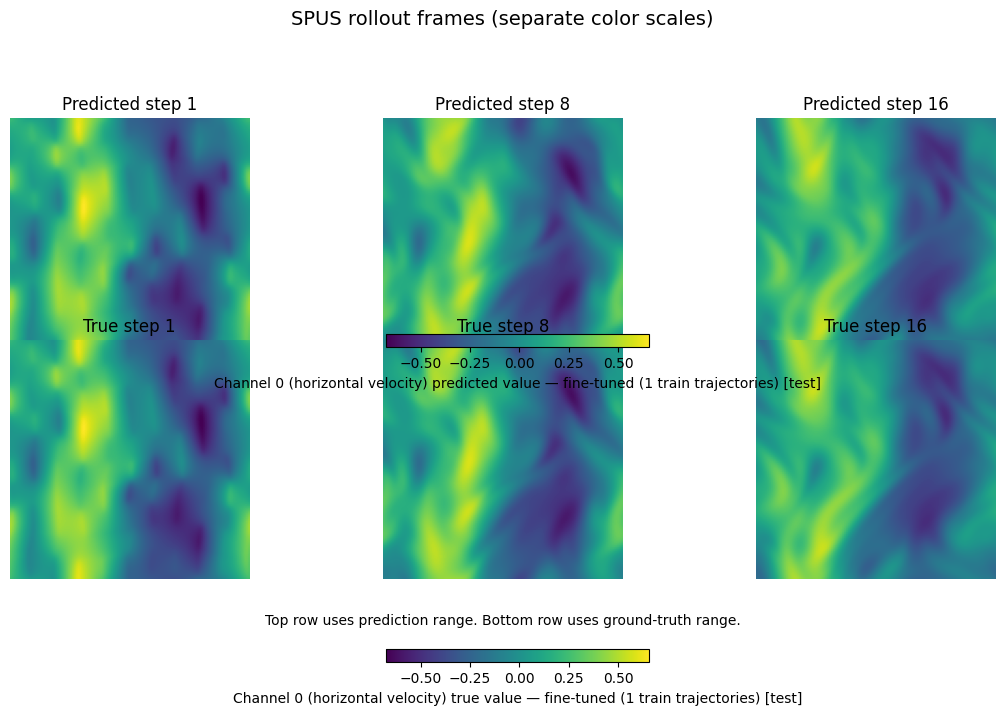

In [7]:
from spus_ft import plot_rollout_frames_separate_scales

plot_rollout_frames_separate_scales(
    run_dir=baseline_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
)


{'figure': <Figure size 1200x1000 with 11 Axes>,
 'axes': array([[<Axes: title={'center': 'Predicted step 1'}>,
         <Axes: title={'center': 'Predicted step 8'}>,
         <Axes: title={'center': 'Predicted step 16'}>],
        [<Axes: title={'center': 'True step 1'}>,
         <Axes: title={'center': 'True step 8'}>,
         <Axes: title={'center': 'True step 16'}>],
        [<Axes: title={'center': 'Difference step 1'}>,
         <Axes: title={'center': 'Difference step 8'}>,
         <Axes: title={'center': 'Difference step 16'}>]], dtype=object),
 'subtitle': Text(0.5, 0.24, 'Top row: predicted rollout. Middle row: ground truth. Bottom row: prediction minus truth.'),
 'colorbar': <matplotlib.colorbar.Colorbar at 0x14fef832f610>,
 'difference_colorbar': <matplotlib.colorbar.Colorbar at 0x14fef82fb8b0>,
 'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'split_name': 'test',
  'split_strategy': 'fns_kf_paper'

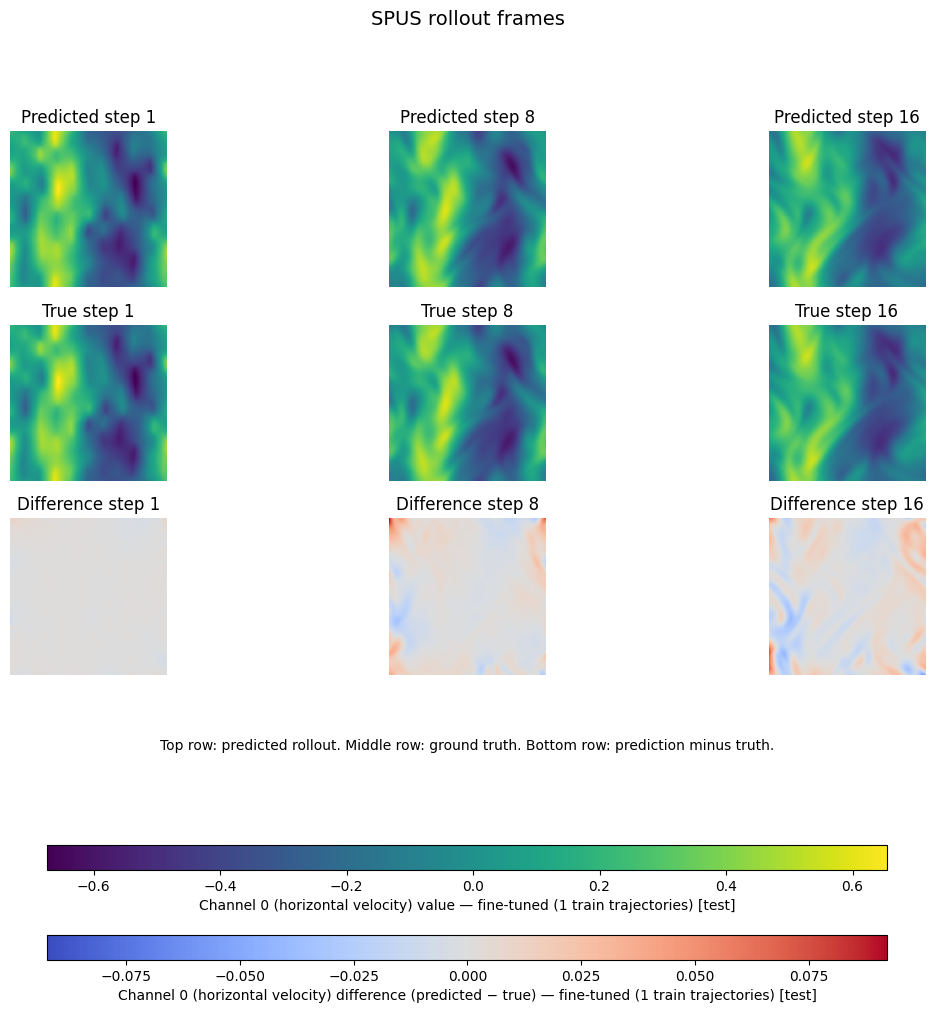

In [8]:
from spus_ft import plot_rollout_frames_separate_scales

plot_rollout_frames(
    run_dir=baseline_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
)


In [10]:
from spus_ft.results import load_torch_rollout, summarize_rollout_prediction_range
import torch

payload = load_torch_rollout(baseline_rollout_outcome["run_dir"], torch_module=torch)
range_summary = summarize_rollout_prediction_range(payload["predictions"])
print(range_summary)

{'min': -0.6728068590164185, 'max': 0.7245588302612305}


{'figure': <Figure size 1200x750 with 8 Axes>,
 'axes': array([[<Axes: title={'center': 'Predicted step 1'}>,
         <Axes: title={'center': 'Predicted step 8'}>,
         <Axes: title={'center': 'Predicted step 16'}>],
        [<Axes: title={'center': 'True step 1'}>,
         <Axes: title={'center': 'True step 8'}>,
         <Axes: title={'center': 'True step 16'}>]], dtype=object),
 'subtitle': Text(0.5, 0.16, 'Top row uses prediction range. Bottom row uses ground-truth range.'),
 'prediction_colorbar': <matplotlib.colorbar.Colorbar at 0x145588e38b80>,
 'target_colorbar': <matplotlib.colorbar.Colorbar at 0x145588e23580>,
 'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'split_name': 'test',
  'split_strategy': 'fns_kf_paper',
  'num_train_trajectories': 1,
  'requested_test_trajectory_index': 0,
  'selected_test_trajectory_index': 19760,
  'test_trajectory_indices': [19760],
  'num_test_trajectories': 1,
  's

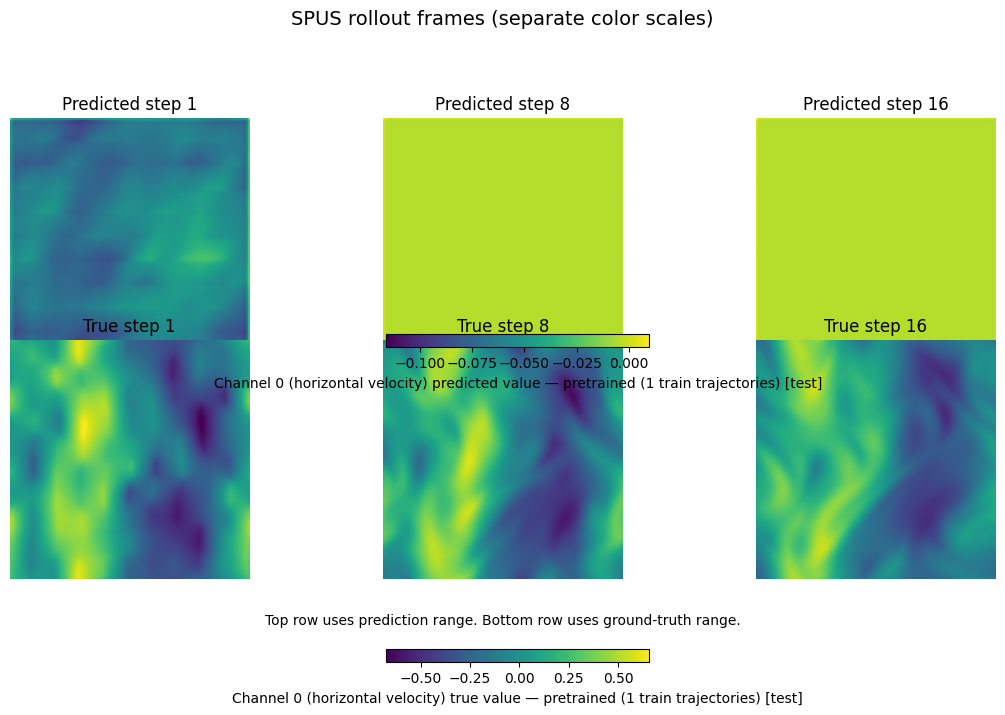

In [14]:
from spus_ft import plot_rollout_frames_separate_scales

plot_rollout_frames_separate_scales(
    run_dir=baseline_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=baseline_rollout_outcome["run_dir"] / "baseline_v2_fig3_like_separate_scales.png",
)


{'figure': <Figure size 1200x700 with 7 Axes>,
 'axes': array([[<Axes: title={'center': 'Predicted step 1'}>,
         <Axes: title={'center': 'Predicted step 8'}>,
         <Axes: title={'center': 'Predicted step 16'}>],
        [<Axes: title={'center': 'True step 1'}>,
         <Axes: title={'center': 'True step 8'}>,
         <Axes: title={'center': 'True step 16'}>]], dtype=object),
 'subtitle': Text(0.5, 0.14, 'Top row: predicted rollout. Bottom row: ground truth.'),
 'colorbar': <matplotlib.colorbar.Colorbar at 0x145589310ee0>,
 'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'split_name': 'test',
  'split_strategy': 'fns_kf_paper',
  'num_train_trajectories': 1,
  'requested_test_trajectory_index': 0,
  'selected_test_trajectory_index': 19760,
  'test_trajectory_indices': [19760],
  'num_test_trajectories': 1,
  'split_info': {'data_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
   'varia

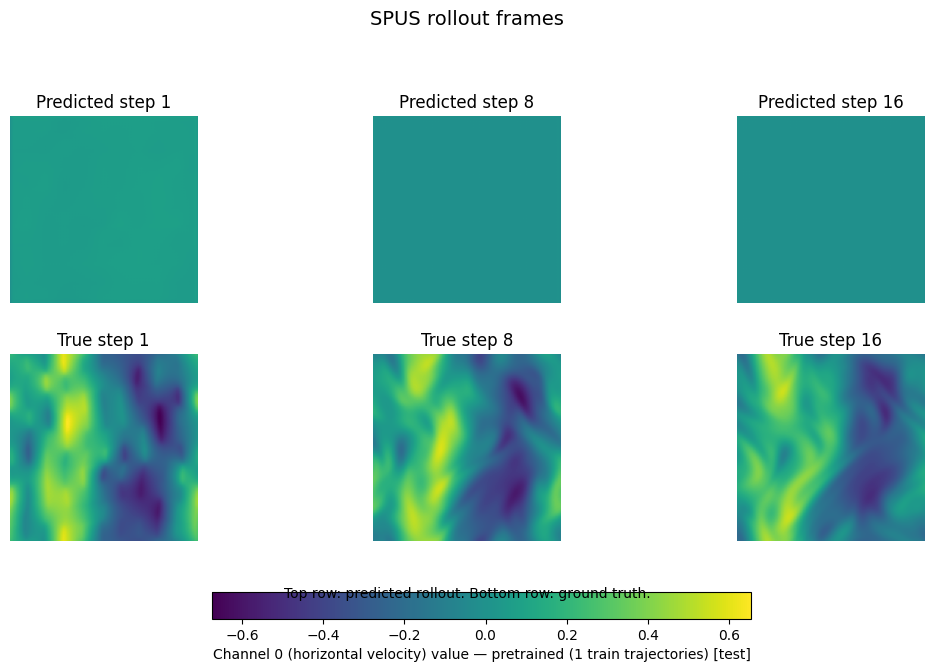

In [8]:
plot_rollout_frames(
    run_dir=baseline_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=baseline_rollout_outcome["run_dir"] / "baseline_v2_fig3_like_rollout.png",
)


## 2. User fine-tuning from the v2 baseline

Fine-tune the pretrained SPUS U-Net v2 model on FNS-KF and save the resulting checkpoint into `spus-ft-runs`.


In [9]:
finetune_outcome = fine_tune(
    dataset_path=dataset_path,
    pretrained_source=pretrained_v2_model_dir,
    num_train_trajectories=16,
    epochs=10,
)

finetune_outcome


[2026-10-22 23:49:35] Constructed in-memory train/val/test trajectory splits from assembled NetCDF file /vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc: variable=solution, shape=(20000, 21, 2, 128, 128), split_strategy=fns_kf_paper, train_trajectories=16, val_trajectories=120, test_trajectories=240, target_channels=5, pad_value=1.0
[2026-10-22 23:49:35] Created data loaders: train_batches=80, val_batches=600, batch_size=4, num_workers=0
Loading weights from local directory
[2026-10-22 23:49:40] Starting fine-tune: dataset=/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc, pretrained_source=/vast/projects/artimis/cahrens/tut-aux/spus-models/spus-pde-unet-36m-v2, epochs=10, batch_size=4, learning_rate=0.0001, train_trajectories=16, val_trajectories=120, test_trajectories=240, device=cuda
[2026-10-22 23:49:40] Starting epoch 1/10
[2026-10-22 23:49:50] Completed epoch 1/10: train_loss=0.019705, val_loss=0.000661
[2026-10-22 23:49:50] New best checkpoint at epoch 1: val_loss=0

{'run_dir': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/fine_tune_spus_36m_20261022-234935'),
 'log_path': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/fine_tune_spus_36m_20261022-234935/training.log'),
 'checkpoint_path': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/fine_tune_spus_36m_20261022-234935/best_checkpoint.pt'),
 'metadata': {'pretrained_model_id': 'siddik-lanl/spus-pde-unet-36m-v2',
  'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'epochs': 10,
  'batch_size': 4,
  'learning_rate': 0.0001,
  'seed': 42,
  'device': 'cuda',
  'target_channels': 5,
  'pad_value': 1.0,
  'split_strategy': 'fns_kf_paper',
  'num_train_trajectories': 16,
  'num_val_trajectories': 120,
  'num_test_trajectories': 240,
  'split_info': {'data_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
   'variable_name': 'solution',
   'shape': (20000, 21, 2, 128, 128),
   'num_traj

## 3. Inference and evaluation of the user checkpoint

Run autoregressive inference with your newly fine-tuned checkpoint, then evaluate without rerunning inference.


In [10]:
user_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=pretrained_v2_model_dir,
    checkpoint_path=finetune_outcome["checkpoint_path"],
)

user_rollout_outcome


Loading weights from local directory


{'run_dir': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261022-235116'),
 'predictions_path': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261022-235116/rollout.pt'),
 'summary_path': PosixPath('/usr/projects/artimis/cahrens/tut-aux/spus-ft-runs/infer_rollout_spus_36m_finetuned_20261022-235116/summary.json'),
 'summary': {'average_mse': 0.012949656173568188,
  'timestep_mse': [6.299356721583444e-05,
   0.00015414903463014255,
   0.0003038061672956646,
   0.0005590299041307089,
   0.0009805848266139915,
   0.0016466357920425344,
   0.002639434172362588,
   0.004038477876536456,
   0.005872062978259168,
   0.008219373893143042,
   0.010974154249204645,
   0.013870337161208007,
   0.0167829277780231,
   0.019675989113250664,
   0.022462645332250262,
   0.025065162326025986,
   0.027607991594021053,
   0.030076107170858662,
   0.03266462861809485,
   0.03533663191619641],
  'metadata': 

{'figure': <Figure size 1200x1000 with 11 Axes>,
 'axes': array([[<Axes: title={'center': 'Predicted step 1'}>,
         <Axes: title={'center': 'Predicted step 8'}>,
         <Axes: title={'center': 'Predicted step 16'}>],
        [<Axes: title={'center': 'True step 1'}>,
         <Axes: title={'center': 'True step 8'}>,
         <Axes: title={'center': 'True step 16'}>],
        [<Axes: title={'center': 'Difference step 1'}>,
         <Axes: title={'center': 'Difference step 8'}>,
         <Axes: title={'center': 'Difference step 16'}>]], dtype=object),
 'subtitle': Text(0.5, 0.24, 'Top row: predicted rollout. Middle row: ground truth. Bottom row: prediction minus truth.'),
 'colorbar': <matplotlib.colorbar.Colorbar at 0x14fed0a40be0>,
 'difference_colorbar': <matplotlib.colorbar.Colorbar at 0x14fed09e0eb0>,
 'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
  'variable_name': 'solution',
  'split_name': 'test',
  'split_strategy': 'fns_kf_paper'

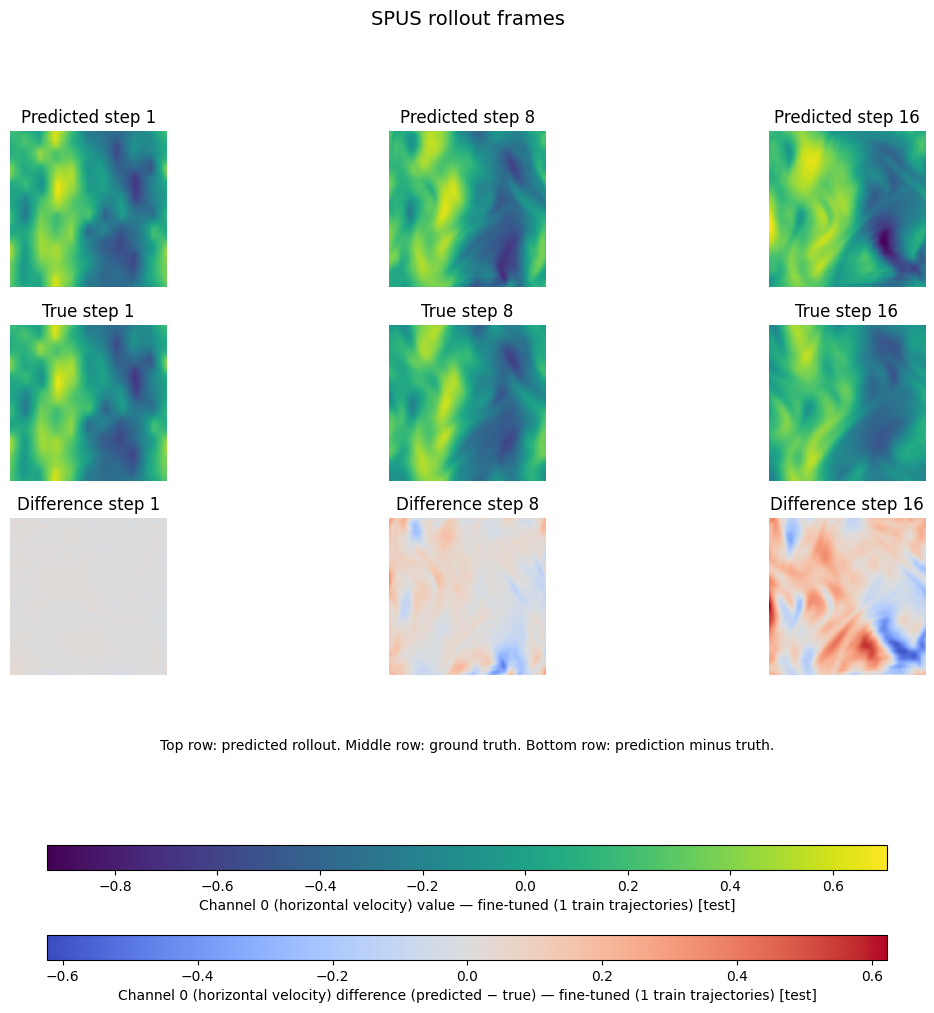

In [11]:
plot_rollout_frames(
    run_dir=user_rollout_outcome["run_dir"],
    trajectory_index=0,
    timesteps=(1, 8, 16),
    channel_index=0,
    channel_names=fns_kf_channel_names,
    save_path=user_rollout_outcome["run_dir"] / "user_finetuned_fig3_like_rollout.png",
)


[2026-10-22 23:54:15] Evaluation complete: split=test, num_trajectories=1, average_mse=0.012950


{'figure': <Figure size 800x450 with 1 Axes>,
 'ax': <Axes: title={'center': 'Average MSE by rollout step'}, xlabel='Rollout step', ylabel='Average MSE'>,
 'evaluation': {'average_mse': 0.012949656173568188,
  'timestep_mse': [6.299356721583444e-05,
   0.00015414903463014255,
   0.0003038061672956646,
   0.0005590299041307089,
   0.0009805848266139915,
   0.0016466357920425344,
   0.002639434172362588,
   0.004038477876536456,
   0.005872062978259168,
   0.008219373893143042,
   0.010974154249204645,
   0.013870337161208007,
   0.0167829277780231,
   0.019675989113250664,
   0.022462645332250262,
   0.025065162326025986,
   0.027607991594021053,
   0.030076107170858662,
   0.03266462861809485,
   0.03533663191619641],
  'per_trajectory_mse': [0.01294965617356819],
  'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
   'variable_name': 'solution',
   'split_name': 'test',
   'split_strategy': 'fns_kf_paper',
   'num_train_trajectories': 1,
   'reque

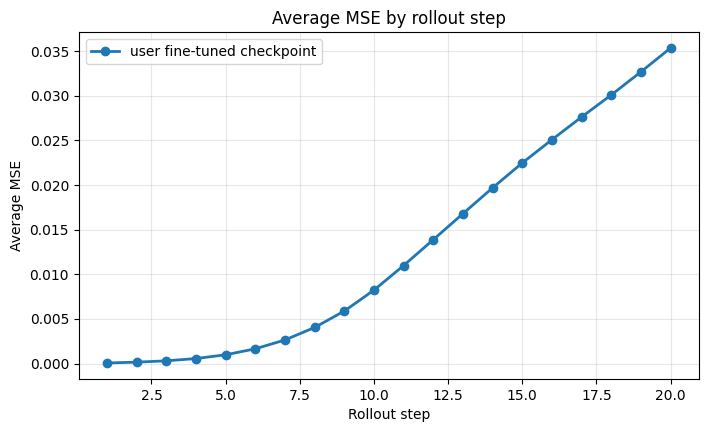

In [14]:
user_evaluation_outcome = evaluate_rollout(
    rollout_outcome=user_rollout_outcome,
)

plot_rollout_mse_curve(
    user_evaluation_outcome["evaluation_path"],
    label="user fine-tuned checkpoint",
)


## 4. Optional comparison against the three Hugging Face fine-tuned models

Evaluate the pretrained v2 baseline and the three published fine-tuned v2 models, then compare their rollout MSE curves against your own checkpoint.


In [12]:
baseline_evaluation_outcome = evaluate_rollout(
    rollout_outcome=baseline_rollout_outcome,
)

hf_fns_kf_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=hf_finetuned_model_dir,
)
hf_fns_kf_evaluation_outcome = evaluate_rollout(rollout_outcome=hf_fns_kf_rollout_outcome)

hf_fns_kf_32_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=hf_finetuned_model_dir_32,
)
hf_fns_kf_32_evaluation_outcome = evaluate_rollout(rollout_outcome=hf_fns_kf_32_rollout_outcome)

hf_fns_kf_256_rollout_outcome = infer_rollout(
    dataset_path=dataset_path,
    split_name="test",
    test_trajectory_index=0,
    pretrained_source=hf_finetuned_model_dir_256,
)
hf_fns_kf_256_evaluation_outcome = evaluate_rollout(rollout_outcome=hf_fns_kf_256_rollout_outcome)


[2026-10-22 23:53:41] Evaluation complete: split=test, num_trajectories=1, average_mse=0.000078
Loading weights from local directory
[2026-10-22 23:53:43] Evaluation complete: split=test, num_trajectories=1, average_mse=0.000706
Loading weights from local directory
[2026-10-22 23:53:45] Evaluation complete: split=test, num_trajectories=1, average_mse=0.010609
Loading weights from local directory
[2026-10-22 23:53:47] Evaluation complete: split=test, num_trajectories=1, average_mse=0.000078


{'figure': <Figure size 850x500 with 1 Axes>,
 'ax': <Axes: title={'center': 'Average MSE by rollout step for FNS-KF'}, xlabel='Rollout step', ylabel='Average MSE'>,
 'evaluations': [{'average_mse': 7.821326132328051e-05,
   'timestep_mse': [1.6754897732491204e-06,
    5.414591094726636e-06,
    1.1128150188737441e-05,
    1.8926126380943994e-05,
    2.859317502069147e-05,
    3.9157520323526735e-05,
    4.967838973805476e-05,
    5.942649538357342e-05,
    6.792419777773849e-05,
    7.568306676711847e-05,
    8.396512426554406e-05,
    9.307143350544467e-05,
    0.00010256430689530331,
    0.00011155323976141502,
    0.00011968217319939447,
    0.00012699270104460047,
    0.0001335281195947336,
    0.00013932363608816872,
    0.0001449694723685743,
    0.00015100781729407076],
   'per_trajectory_mse': [7.821326132328051e-05],
   'metadata': {'dataset_path': '/vast/projects/exalearn/cahrens/PDEgym/FNS-KF/FNS-KF.nc',
    'variable_name': 'solution',
    'split_name': 'test',
    'split_

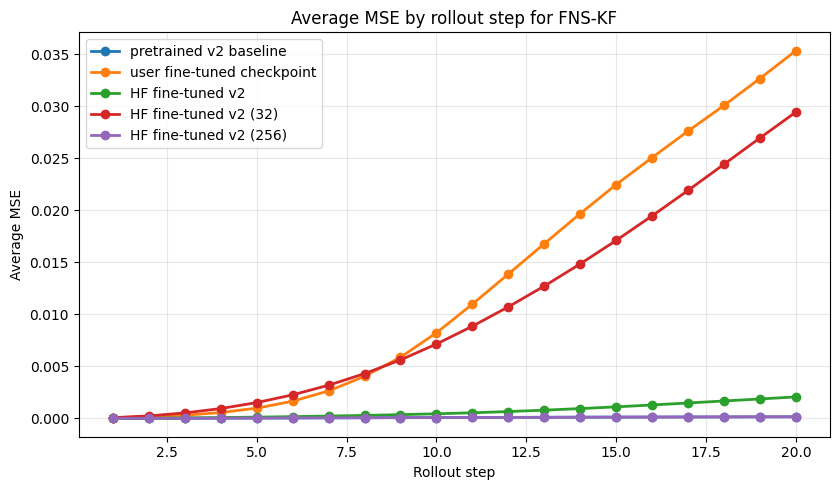

In [15]:
plot_multiple_rollout_mse_curves(
    [
        baseline_evaluation_outcome["evaluation_path"],
        user_evaluation_outcome["evaluation_path"],
        hf_fns_kf_evaluation_outcome["evaluation_path"],
        hf_fns_kf_32_evaluation_outcome["evaluation_path"],
        hf_fns_kf_256_evaluation_outcome["evaluation_path"],
    ],
    labels=[
        "pretrained v2 baseline",
        "user fine-tuned checkpoint",
        "HF fine-tuned v2",
        "HF fine-tuned v2 (32)",
        "HF fine-tuned v2 (256)",
    ],
    save_path=comparison_output_dir / "fns_kf_mse_compare.png",
)
